# Heart Disease Prediction using Decision Tree + Logistic Regression

**Course:** Machine Learning  
**Instructor:** Alassane Diallo  
**Dataset:** Heart Failure Prediction Dataset (Kaggle)  
**Algorithms:** Decision Tree (from scratch) · Logistic Regression (from scratch)  
**Task:** Binary Classification — Predict the presence of heart disease


## 1. Problem Statement

Cardiovascular diseases are the leading cause of death globally. This project addresses:

> **Can we predict whether a patient has heart disease based on clinical features, and do from-scratch implementations reproduce library-grade results?**

We implement two algorithms from scratch — a Decision Tree Classifier and a Logistic Regression Classifier — and compare both against their scikit-learn equivalents on identical data splits.

**Dataset source:** https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction


## 2. Imports and Setup


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from collections import Counter
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression as SKLearnLR
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11
sns.set_theme(style='whitegrid')
print('All imports successful.')


All imports successful.


## 3. Data Loading and Exploration


In [2]:
df = pd.read_csv('heart.csv')
print(f'Shape: {df.shape}')
df.head(10)


Shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
5,39,M,NAP,120,339,0,Normal,170,N,0.0,Up,0
6,45,F,ATA,130,237,0,Normal,170,N,0.0,Up,0
7,54,M,ATA,110,208,0,Normal,142,N,0.0,Up,0
8,37,M,ASY,140,207,0,Normal,130,Y,1.5,Flat,1
9,48,F,ATA,120,284,0,Normal,120,N,0.0,Up,0


In [3]:
print('Data types:')
print(df.dtypes)
print('\nMissing values:')
print(df.isnull().sum())
print('\nClass distribution:')
print(df['HeartDisease'].value_counts())


Data types:
Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object

Missing values:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Class distribution:
HeartDisease
1    508
0    410
Name: count, dtype: int64


In [4]:
df.describe()


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


### 3.1 Exploratory Visualizations


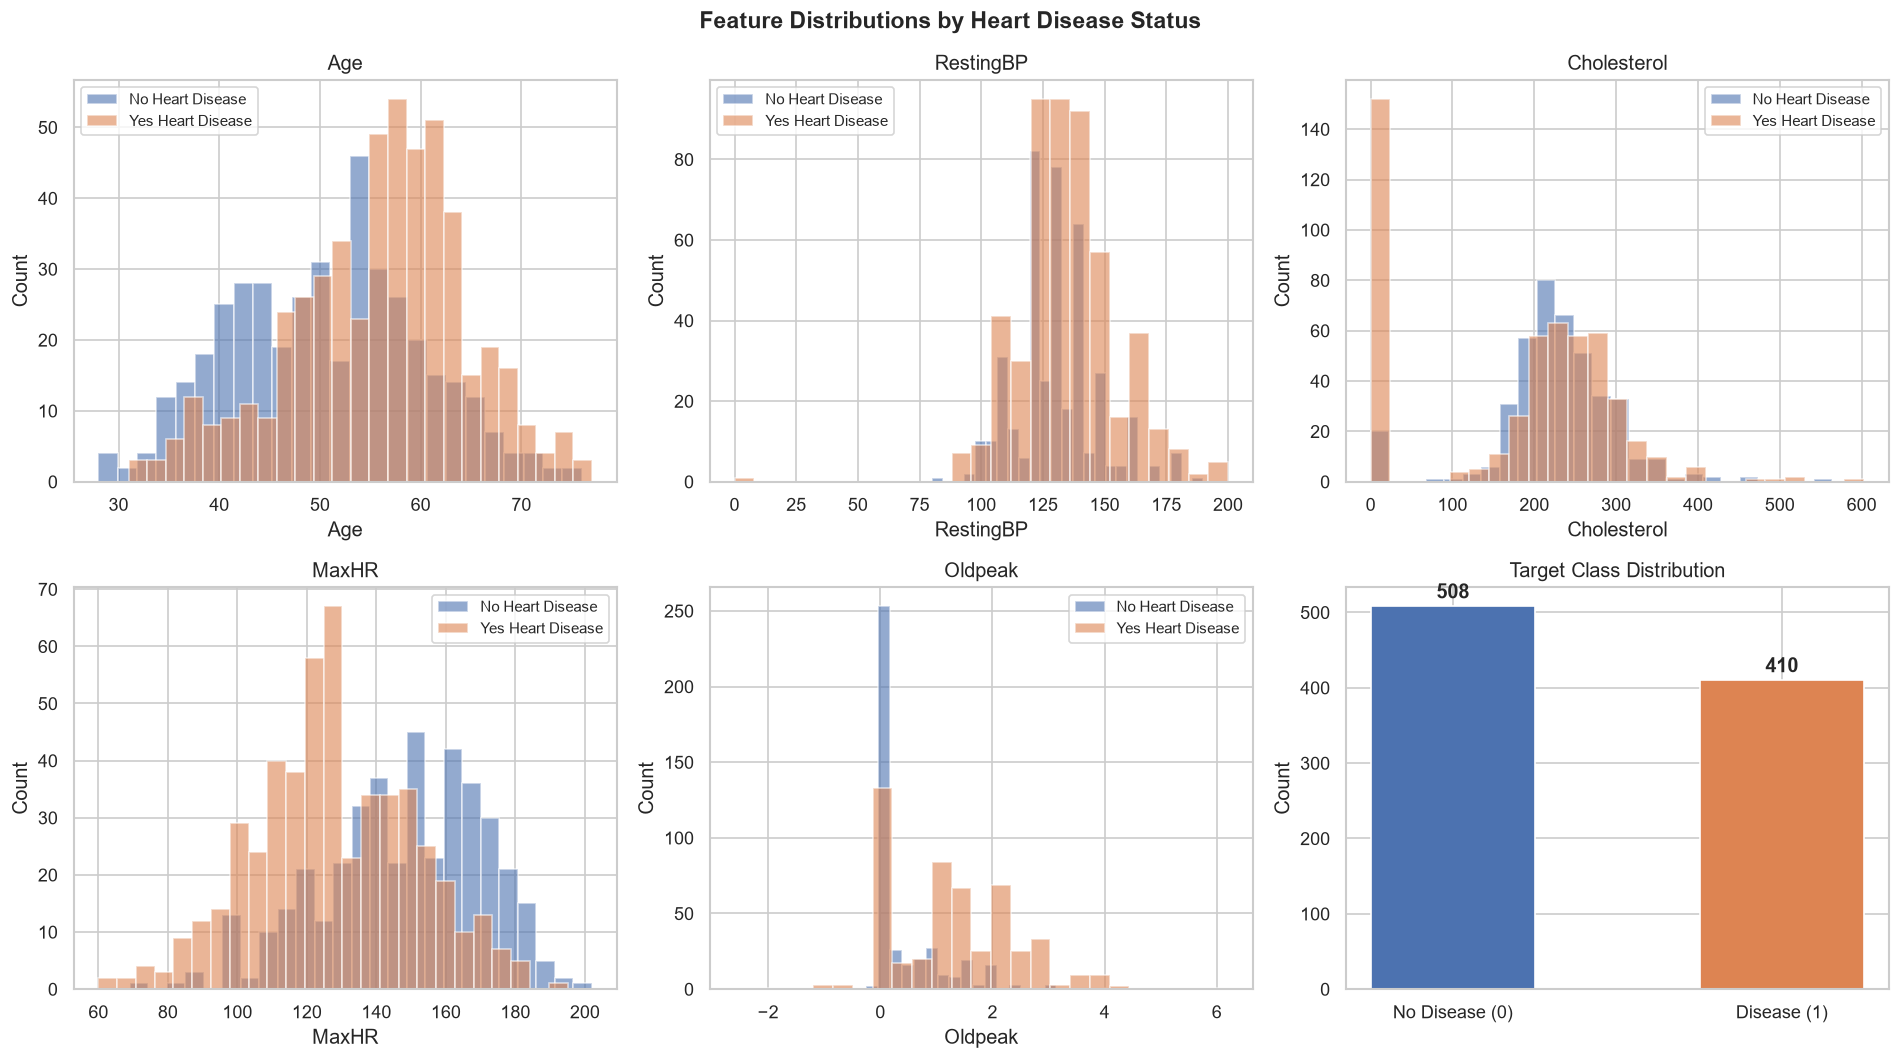

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('Feature Distributions by Heart Disease Status', fontsize=14, fontweight='bold')

num_features = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
palette = {0: '#4C72B0', 1: '#DD8452'}

for ax, feat in zip(axes.flat, num_features):
    for label, grp in df.groupby('HeartDisease'):
        ax.hist(grp[feat], bins=25, alpha=0.6,
                label=f'{"No" if label==0 else "Yes"} Heart Disease',
                color=palette[label], edgecolor='white')
    ax.set_title(feat); ax.set_xlabel(feat); ax.set_ylabel('Count')
    ax.legend(fontsize=9)

ax6 = axes[1, 2]
counts = df['HeartDisease'].value_counts()
bars = ax6.bar(['No Disease (0)', 'Disease (1)'], counts.values,
               color=[palette[0], palette[1]], edgecolor='white', width=0.5)
for bar, count in zip(bars, counts.values):
    ax6.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
             str(count), ha='center', va='bottom', fontweight='bold')
ax6.set_title('Target Class Distribution'); ax6.set_ylabel('Count')

plt.tight_layout()
plt.savefig('fig1_feature_distributions.png', bbox_inches='tight')
plt.show()


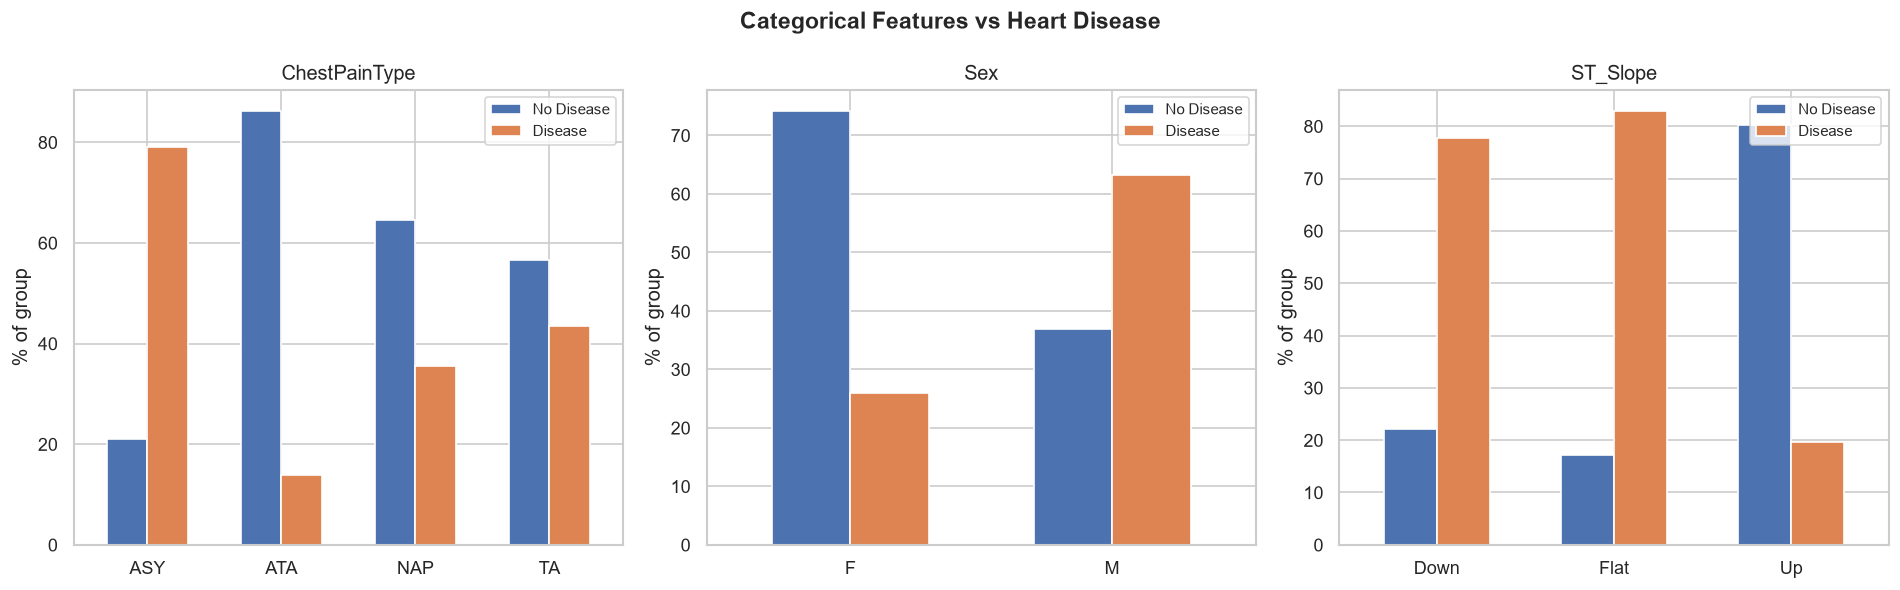

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Categorical Features vs Heart Disease', fontsize=14, fontweight='bold')

cat_features = ['ChestPainType', 'Sex', 'ST_Slope']
for ax, feat in zip(axes, cat_features):
    ct = pd.crosstab(df[feat], df['HeartDisease'], normalize='index') * 100
    ct.plot(kind='bar', ax=ax, color=[palette[0], palette[1]], edgecolor='white', width=0.6)
    ax.set_title(feat); ax.set_xlabel(''); ax.set_ylabel('% of group')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(['No Disease', 'Disease'], fontsize=9)

plt.tight_layout()
plt.savefig('fig2_categorical_features.png', bbox_inches='tight')
plt.show()


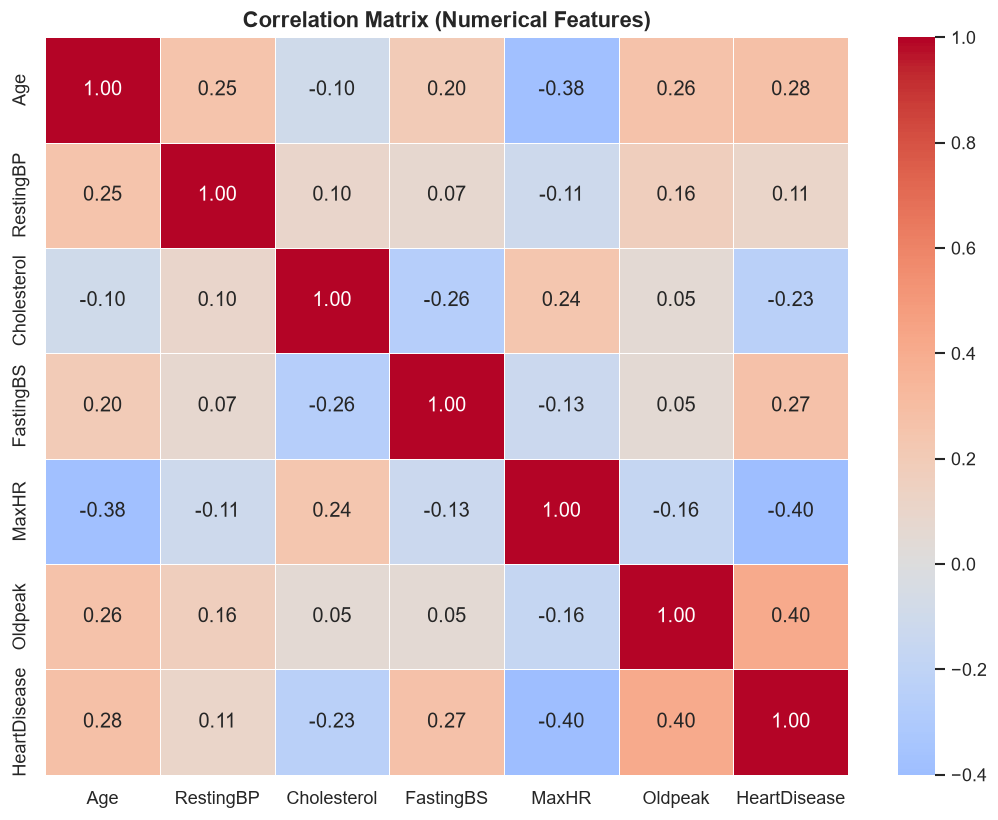

In [7]:
num_df = df.select_dtypes(include=[np.number])
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(num_df.corr(), annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, ax=ax)
ax.set_title('Correlation Matrix (Numerical Features)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig3_correlation_heatmap.png', bbox_inches='tight')
plt.show()


## 4. Data Preprocessing

No missing values were found in the raw data. However, Cholesterol (172 records) and RestingBP (1 record) contain physiologically impossible zero values — treated as coded missings and replaced with the column median computed from non-zero rows. Categorical features are one-hot encoded. Numerical features are **additionally standardised** for Logistic Regression (Decision Trees are scale-invariant so no scaling is applied to them).


In [8]:
df_clean = df.copy()

# Impute invalid zeros
chol_median = df_clean.loc[df_clean['Cholesterol'] > 0, 'Cholesterol'].median()
zero_chol = (df_clean['Cholesterol'] == 0).sum()
df_clean.loc[df_clean['Cholesterol'] == 0, 'Cholesterol'] = chol_median
print(f'Cholesterol zeros replaced: {zero_chol} -> imputed with median {chol_median}')

bp_median = df_clean.loc[df_clean['RestingBP'] > 0, 'RestingBP'].median()
zero_bp = (df_clean['RestingBP'] == 0).sum()
df_clean.loc[df_clean['RestingBP'] == 0, 'RestingBP'] = bp_median
print(f'RestingBP zeros replaced: {zero_bp} -> imputed with median {bp_median}')

# One-hot encode categorical columns
cat_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
df_encoded = pd.get_dummies(df_clean, columns=cat_cols, drop_first=False)

X = df_encoded.drop('HeartDisease', axis=1)
y = df_encoded['HeartDisease'].values
feature_names = list(X.columns)

print(f'\nFeature matrix shape: {X.shape}')
print(f'Feature names: {feature_names}')


Cholesterol zeros replaced: 172 -> imputed with median 237.0
RestingBP zeros replaced: 1 -> imputed with median 130.0

Feature matrix shape: (918, 20)
Feature names: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'Sex_F', 'Sex_M', 'ChestPainType_ASY', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_LVH', 'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_N', 'ExerciseAngina_Y', 'ST_Slope_Down', 'ST_Slope_Flat', 'ST_Slope_Up']


In [9]:
# Train / Validation / Test split: 70% / 15% / 15%
X_arr = X.values.astype(float)

X_train, X_temp, y_train, y_temp = train_test_split(
    X_arr, y, test_size=0.30, random_state=RANDOM_SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_SEED, stratify=y_temp
)

print(f'Train:      {X_train.shape[0]} samples')
print(f'Validation: {X_val.shape[0]} samples')
print(f'Test:       {X_test.shape[0]} samples')
print(f'\nClass balance in train: {Counter(y_train)}')
print(f'Class balance in test:  {Counter(y_test)}')

# Standardised copies for Logistic Regression
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc   = scaler.transform(X_val)
X_test_sc  = scaler.transform(X_test)
print('\nStandardised copies created for Logistic Regression.')


Train:      642 samples
Validation: 138 samples
Test:       138 samples

Class balance in train: Counter({np.int64(1): 355, np.int64(0): 287})
Class balance in test:  Counter({np.int64(1): 76, np.int64(0): 62})

Standardised copies created for Logistic Regression.


## 5. Mathematical Formulation

### 5.1 Decision Tree

**Gini Impurity:**

Given a node with $n$ samples from $K$ classes, where $p_k$ is the proportion of class $k$:

```
G(p) = 1 - sum(p_k^2)   for k = 1...K
```

G = 0 when all samples share one class (pure node). G is maximised at 0.5 for a two-class node with equal proportions.

**Gini Gain** — for a candidate split of parent node $t$ ($n$ samples) into left child ($n_L$ samples) and right child ($n_R$ samples):

```
deltaG(t, j, theta) = G(t) - (n_L/n)*G(t_L) - (n_R/n)*G(t_R)
```

We search all features $j$ and midpoint thresholds $\theta$ to select the split that **maximises deltaG**.

**Stopping Conditions** — recursion terminates when ANY of the following holds:

1. Current depth reaches `max_depth` (depth >= max_depth)
2. Node has fewer than `min_samples_split` samples (< 2)
3. Node is already pure: G = 0
4. No candidate split yields deltaG > 0 (no impurity improvement possible)

**Leaf Prediction** — majority class among the node's training samples:

```
y_hat = argmax_k  |{i : y_i = k}|
```

**Feature Importance** — for each feature $j$, accumulate the total sample-weighted Gini decrease across all tree nodes that split on $j$, then normalise:

```
I(j) = sum over all nodes t where (split feature = j):  n_t * deltaG(t, j, theta_t)

Normalised:  I(j)  <-  I(j) / sum_j I(j)     (importances sum to 1)
```

This is the 'mean decrease in impurity' criterion, identical to scikit-learn's implementation.

---

### 5.2 Logistic Regression

**Sigmoid (logistic) function:**

The probability that sample $x$ belongs to class 1 is modelled as:

```
sigma(z) = 1 / (1 + exp(-z)),   z = w^T x + b
```

Predicted class: 1 when sigma(z) >= 0.5, i.e. when z >= 0.

**Numerical Stability:**

- `exp(-z)` overflows (to infinity) for very negative $z$. Fix: clip $z$ to $[-500, 500]$ before computing exp.
- `log(0)` is undefined. Fix: clip $\hat{p}$ to $[10^{-15},\, 1-10^{-15}]$ before computing the log in the loss.

**Binary Cross-Entropy Loss (Objective Function):**

For $n$ training samples, we minimise the negative log-likelihood:

```
L(w, b) = -(1/n) * sum_i [ y_i*log(p_hat_i) + (1 - y_i)*log(1 - p_hat_i) ]
```

**Gradients** (derived by chain rule through the sigmoid — the residual $\hat{p} - y$ appears naturally):

```
dL/dw = (1/n) * X^T (p_hat - y)       shape: (p,)
dL/db = (1/n) * sum(p_hat_i - y_i)    scalar
```

**Batch Gradient Descent Updates** (applied every iteration for n_iterations = 2000):

```
w  <-  w - alpha * dL/dw
b  <-  b - alpha * dL/db
```

**Stopping condition:** fixed iteration count. Learning rate $\alpha$ selected by validation-set sweep over {0.001, 0.01, 0.05, 0.1, 0.3, 0.5} — best: $\alpha = 0.001$.


## 6. From-Scratch Decision Tree Implementation


In [10]:
class Node:
    def __init__(self):
        self.feature_index = None
        self.threshold = None
        self.left = None
        self.right = None
        self.value = None
        self.gini = None
        self.n_samples = None


class DecisionTreeScratch:
    """
    Binary Decision Tree Classifier — Gini impurity, from scratch.

    Parameters
    ----------
    max_depth : int or None
    min_samples_split : int
    """

    def __init__(self, max_depth=None, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.root = None
        self.feature_importances_ = None

    def _gini(self, y):
        n = len(y)
        if n == 0:
            return 0.0
        counts = np.bincount(y)
        probs = counts / n
        return 1.0 - np.sum(probs ** 2)

    def _best_split(self, X, y):
        n, n_features = X.shape
        parent_gini = self._gini(y)
        best_gain, best_feature, best_threshold = -1.0, None, None

        for feature_idx in range(n_features):
            col = X[:, feature_idx]
            unique_vals = np.unique(col)
            thresholds = (unique_vals[:-1] + unique_vals[1:]) / 2.0

            for threshold in thresholds:
                left_mask = col <= threshold
                right_mask = ~left_mask
                n_left, n_right = left_mask.sum(), right_mask.sum()
                if n_left == 0 or n_right == 0:
                    continue

                weighted_gini = ((n_left / n) * self._gini(y[left_mask]) +
                                 (n_right / n) * self._gini(y[right_mask]))
                gain = parent_gini - weighted_gini

                if gain > best_gain:
                    best_gain, best_feature, best_threshold = gain, feature_idx, threshold

        return best_feature, best_threshold, best_gain

    def _build_tree(self, X, y, depth):
        node = Node()
        node.n_samples = len(y)
        node.gini = self._gini(y)

        if (node.gini == 0.0 or
                len(y) < self.min_samples_split or
                (self.max_depth is not None and depth >= self.max_depth)):
            node.value = int(np.bincount(y).argmax())
            return node

        best_feature, best_threshold, best_gain = self._best_split(X, y)

        if best_gain <= 0 or best_feature is None:
            node.value = int(np.bincount(y).argmax())
            return node

        node.feature_index = best_feature
        node.threshold = best_threshold
        self._importance_accum[best_feature] += len(y) * best_gain

        mask = X[:, best_feature] <= best_threshold
        node.left  = self._build_tree(X[mask],  y[mask],  depth + 1)
        node.right = self._build_tree(X[~mask], y[~mask], depth + 1)
        return node

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=int)
        self._importance_accum = np.zeros(X.shape[1])
        self.root = self._build_tree(X, y, depth=0)
        total = self._importance_accum.sum()
        self.feature_importances_ = (
            self._importance_accum / total if total > 0 else self._importance_accum
        )
        return self

    def _predict_one(self, x, node):
        if node.value is not None:
            return node.value
        if x[node.feature_index] <= node.threshold:
            return self._predict_one(x, node.left)
        return self._predict_one(x, node.right)

    def predict(self, X):
        X = np.array(X, dtype=float)
        return np.array([self._predict_one(x, self.root) for x in X])

    def _depth(self, node):
        if node is None or node.value is not None:
            return 0
        return 1 + max(self._depth(node.left), self._depth(node.right))

    def get_depth(self):
        return self._depth(self.root)

    def _count_leaves(self, node):
        if node is None:
            return 0
        if node.value is not None:
            return 1
        return self._count_leaves(node.left) + self._count_leaves(node.right)

    def get_n_leaves(self):
        return self._count_leaves(self.root)


print('DecisionTreeScratch class defined.')


DecisionTreeScratch class defined.


## 7. From-Scratch Logistic Regression Implementation


In [11]:
class LogisticRegressionScratch:
    """
    Binary Logistic Regression via batch gradient descent.

    Parameters
    ----------
    lr           : float  — learning rate (alpha)
    n_iterations : int   — number of gradient descent steps
    """

    def __init__(self, lr=0.1, n_iterations=1000):
        self.lr = lr
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = None
        self.loss_history = []

    def _sigmoid(self, z):
        z = np.clip(z, -500, 500)   # prevent overflow
        return 1.0 / (1.0 + np.exp(-z))

    def _cross_entropy(self, y, p_hat):
        p_hat = np.clip(p_hat, 1e-15, 1 - 1e-15)  # prevent log(0)
        return -np.mean(y * np.log(p_hat) + (1 - y) * np.log(1 - p_hat))

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)
        n, p = X.shape

        self.weights = np.zeros(p)
        self.bias = 0.0
        self.loss_history = []

        for _ in range(self.n_iterations):
            # Forward pass
            z = X @ self.weights + self.bias
            p_hat = self._sigmoid(z)

            # Record loss
            self.loss_history.append(self._cross_entropy(y, p_hat))

            # Gradients
            error = p_hat - y            # (n,)
            dw = (X.T @ error) / n      # (p,)
            db = error.mean()

            # Update
            self.weights -= self.lr * dw
            self.bias    -= self.lr * db

        return self

    def predict_proba(self, X):
        X = np.array(X, dtype=float)
        return self._sigmoid(X @ self.weights + self.bias)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


print('LogisticRegressionScratch class defined.')


LogisticRegressionScratch class defined.


## 8. Hyperparameter Tuning

### 8.1 Decision Tree — max_depth sweep


Best max_depth: 4  (val accuracy = 0.8913)


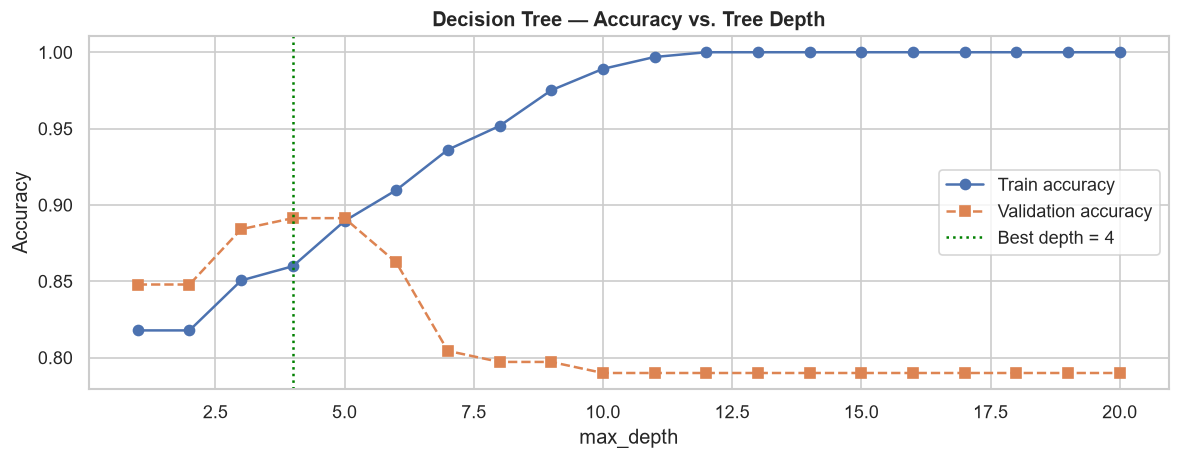

In [12]:
depths = list(range(1, 21))
train_accs_dt, val_accs_dt = [], []

for d in depths:
    clf = DecisionTreeScratch(max_depth=d, min_samples_split=2)
    clf.fit(X_train, y_train)
    train_accs_dt.append(accuracy_score(y_train, clf.predict(X_train)))
    val_accs_dt.append(accuracy_score(y_val,   clf.predict(X_val)))

best_depth = depths[np.argmax(val_accs_dt)]
print(f'Best max_depth: {best_depth}  (val accuracy = {max(val_accs_dt):.4f})')

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(depths, train_accs_dt, 'o-', label='Train accuracy', color='#4C72B0')
ax.plot(depths, val_accs_dt,  's--', label='Validation accuracy', color='#DD8452')
ax.axvline(best_depth, color='green', linestyle=':', linewidth=1.5,
           label=f'Best depth = {best_depth}')
ax.set_xlabel('max_depth'); ax.set_ylabel('Accuracy')
ax.set_title('Decision Tree — Accuracy vs. Tree Depth', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('fig4_dt_depth_tuning.png', bbox_inches='tight')
plt.show()


### 8.2 Logistic Regression — learning rate sweep


Best learning rate: 0.001  (val accuracy = 0.8986)


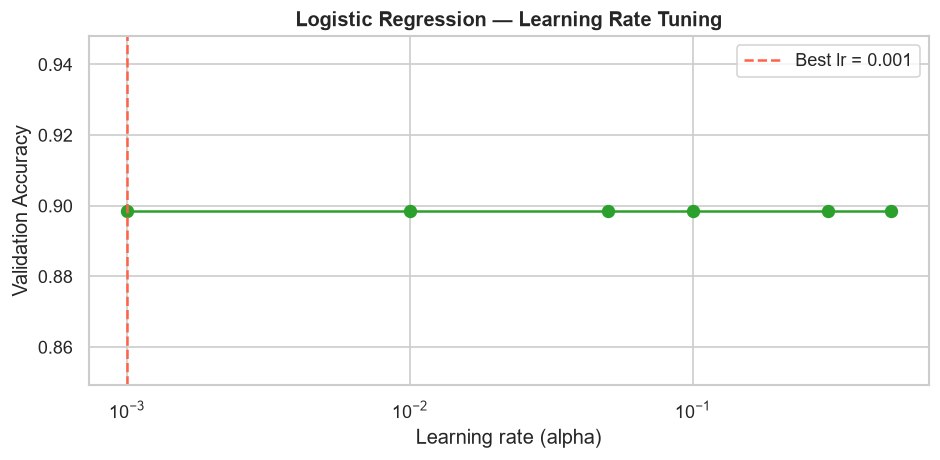

In [13]:
lrs = [0.001, 0.01, 0.05, 0.1, 0.3, 0.5]
lr_val_accs = []

for lr in lrs:
    clf_lr = LogisticRegressionScratch(lr=lr, n_iterations=2000)
    clf_lr.fit(X_train_sc, y_train)
    lr_val_accs.append(accuracy_score(y_val, clf_lr.predict(X_val_sc)))

best_lr = lrs[np.argmax(lr_val_accs)]
print(f'Best learning rate: {best_lr}  (val accuracy = {max(lr_val_accs):.4f})')

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lrs, lr_val_accs, 'o-', color='#2ca02c', markersize=7)
ax.axvline(best_lr, color='tomato', linestyle='--', linewidth=1.5,
           label=f'Best lr = {best_lr}')
ax.set_xlabel('Learning rate (alpha)'); ax.set_ylabel('Validation Accuracy')
ax.set_xscale('log')
ax.set_title('Logistic Regression — Learning Rate Tuning', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('fig5_lr_tuning.png', bbox_inches='tight')
plt.show()


## 9. Final Model Training and Evaluation


In [14]:
# ── Decision Tree ──
scratch_clf = DecisionTreeScratch(max_depth=best_depth, min_samples_split=2)
scratch_clf.fit(X_train, y_train)
y_pred_dt_scratch = scratch_clf.predict(X_test)

sklearn_clf = DecisionTreeClassifier(max_depth=best_depth, criterion='gini',
                                     random_state=RANDOM_SEED)
sklearn_clf.fit(X_train, y_train)
y_pred_dt_sklearn = sklearn_clf.predict(X_test)

print('=== Decision Tree From-Scratch (Test Set) ===')
print(f'Depth: {scratch_clf.get_depth()}  Leaves: {scratch_clf.get_n_leaves()}')
print(classification_report(y_test, y_pred_dt_scratch,
                              target_names=['No Disease', 'Disease']))


=== Decision Tree From-Scratch (Test Set) ===
Depth: 4  Leaves: 15
              precision    recall  f1-score   support

  No Disease       0.80      0.82      0.81        62
     Disease       0.85      0.83      0.84        76

    accuracy                           0.83       138
   macro avg       0.82      0.83      0.82       138
weighted avg       0.83      0.83      0.83       138



In [15]:
# ── Logistic Regression ──
lr_scratch = LogisticRegressionScratch(lr=best_lr, n_iterations=2000)
lr_scratch.fit(X_train_sc, y_train)
y_pred_lr_scratch = lr_scratch.predict(X_test_sc)

lr_sklearn = SKLearnLR(max_iter=2000, random_state=RANDOM_SEED)
lr_sklearn.fit(X_train_sc, y_train)
y_pred_lr_sklearn = lr_sklearn.predict(X_test_sc)

print('=== Logistic Regression From-Scratch (Test Set) ===')
print(classification_report(y_test, y_pred_lr_scratch,
                              target_names=['No Disease', 'Disease']))
print('=== Logistic Regression Scikit-learn (Test Set) ===')
print(classification_report(y_test, y_pred_lr_sklearn,
                              target_names=['No Disease', 'Disease']))


=== Logistic Regression From-Scratch (Test Set) ===
              precision    recall  f1-score   support

  No Disease       0.81      0.90      0.85        62
     Disease       0.91      0.83      0.87        76

    accuracy                           0.86       138
   macro avg       0.86      0.87      0.86       138
weighted avg       0.87      0.86      0.86       138

=== Logistic Regression Scikit-learn (Test Set) ===
              precision    recall  f1-score   support

  No Disease       0.81      0.89      0.85        62
     Disease       0.90      0.83      0.86        76

    accuracy                           0.86       138
   macro avg       0.85      0.86      0.85       138
weighted avg       0.86      0.86      0.86       138



## 10. Results Comparison


In [16]:
def metrics_dict(y_true, y_pred, label):
    return {
        'Model':     label,
        'Accuracy':  round(accuracy_score(y_true, y_pred), 4),
        'Precision': round(precision_score(y_true, y_pred), 4),
        'Recall':    round(recall_score(y_true, y_pred), 4),
        'F1':        round(f1_score(y_true, y_pred), 4),
    }

all_results = pd.DataFrame([
    metrics_dict(y_test, y_pred_dt_scratch, 'Decision Tree (Scratch)'),
    metrics_dict(y_test, y_pred_dt_sklearn, 'Decision Tree (Sklearn)'),
    metrics_dict(y_test, y_pred_lr_scratch, 'Logistic Regression (Scratch)'),
    metrics_dict(y_test, y_pred_lr_sklearn, 'Logistic Regression (Sklearn)'),
]).set_index('Model')

print('=== FULL COMPARISON TABLE ===')
print(all_results.to_string())


=== FULL COMPARISON TABLE ===
                               Accuracy  Precision  Recall     F1
Model                                                            
Decision Tree (Scratch)          0.8261     0.8514  0.8289  0.840
Decision Tree (Sklearn)          0.8261     0.8514  0.8289  0.840
Logistic Regression (Scratch)    0.8623     0.9130  0.8289  0.869
Logistic Regression (Sklearn)    0.8551     0.9000  0.8289  0.863


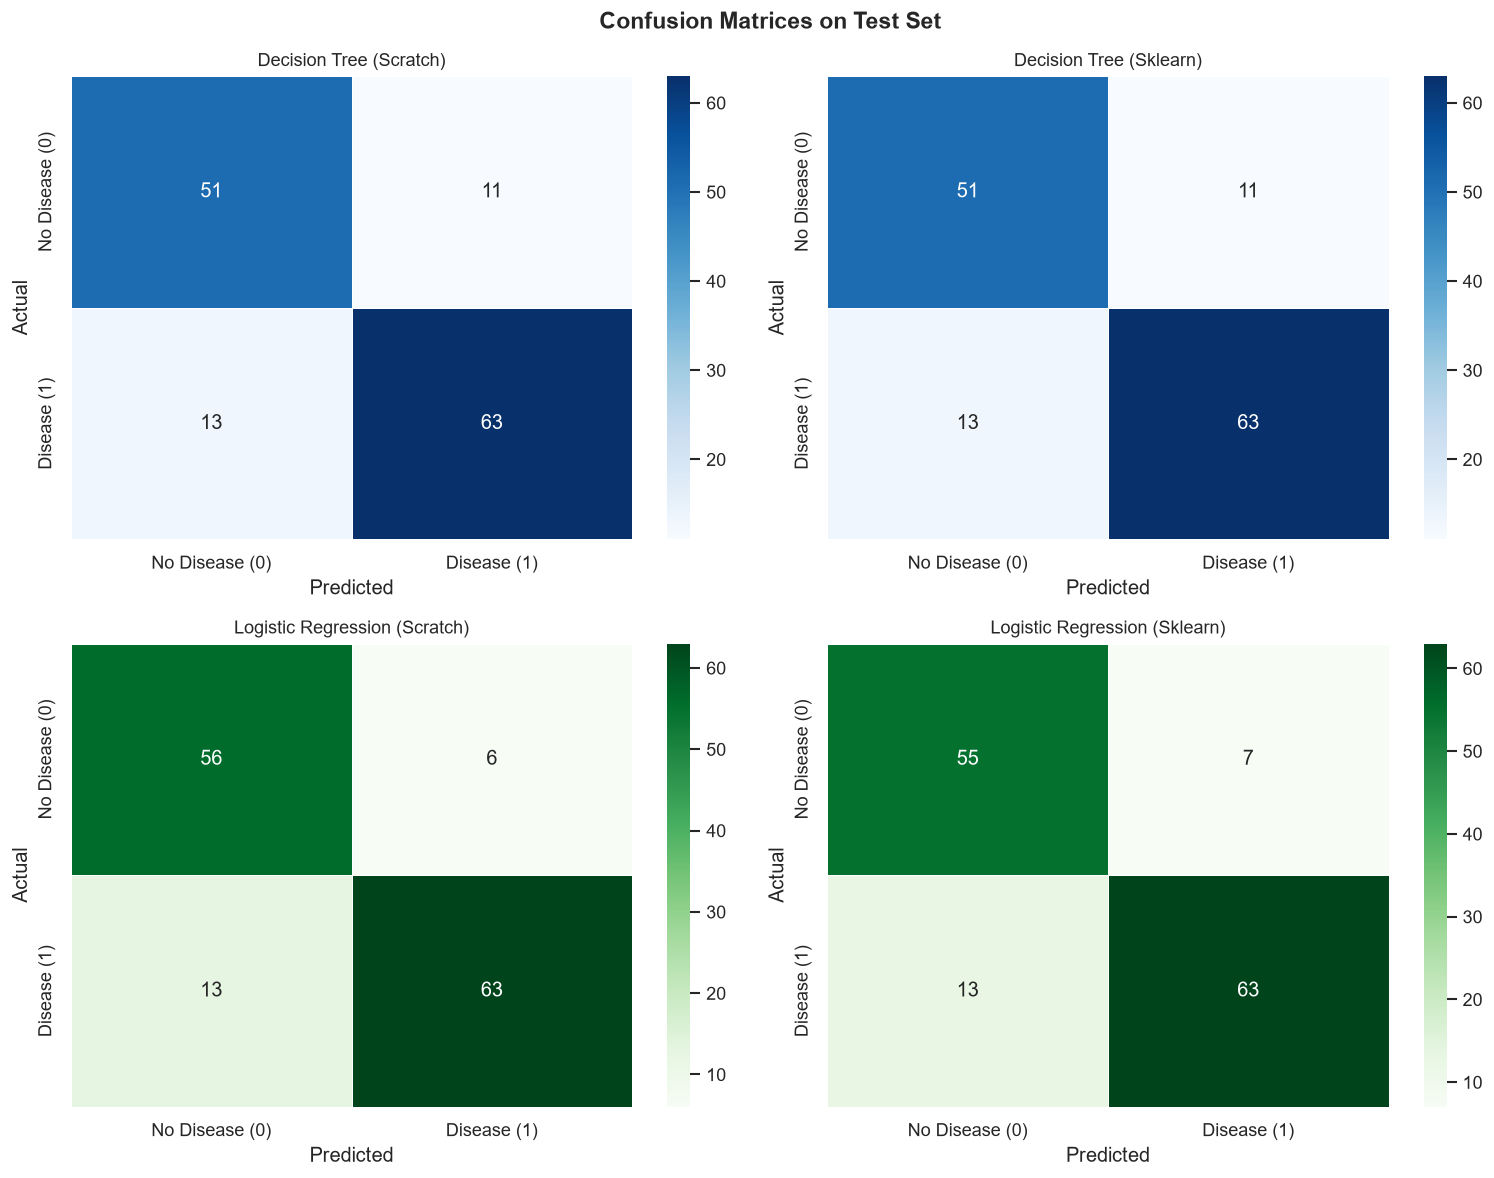

In [17]:
# Confusion matrices — all four models
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
fig.suptitle('Confusion Matrices on Test Set', fontsize=14, fontweight='bold')

labels = ['No Disease (0)', 'Disease (1)']
pairs = [
    (y_pred_dt_scratch, 'Decision Tree (Scratch)',           'Blues'),
    (y_pred_dt_sklearn, 'Decision Tree (Sklearn)',           'Blues'),
    (y_pred_lr_scratch, 'Logistic Regression (Scratch)',     'Greens'),
    (y_pred_lr_sklearn, 'Logistic Regression (Sklearn)',     'Greens'),
]
for ax, (y_pred, title, cmap) in zip(axes.flat, pairs):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=ax,
                xticklabels=labels, yticklabels=labels, linewidths=0.5)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')

plt.tight_layout()
plt.savefig('fig6_all_confusion_matrices.png', bbox_inches='tight')
plt.show()


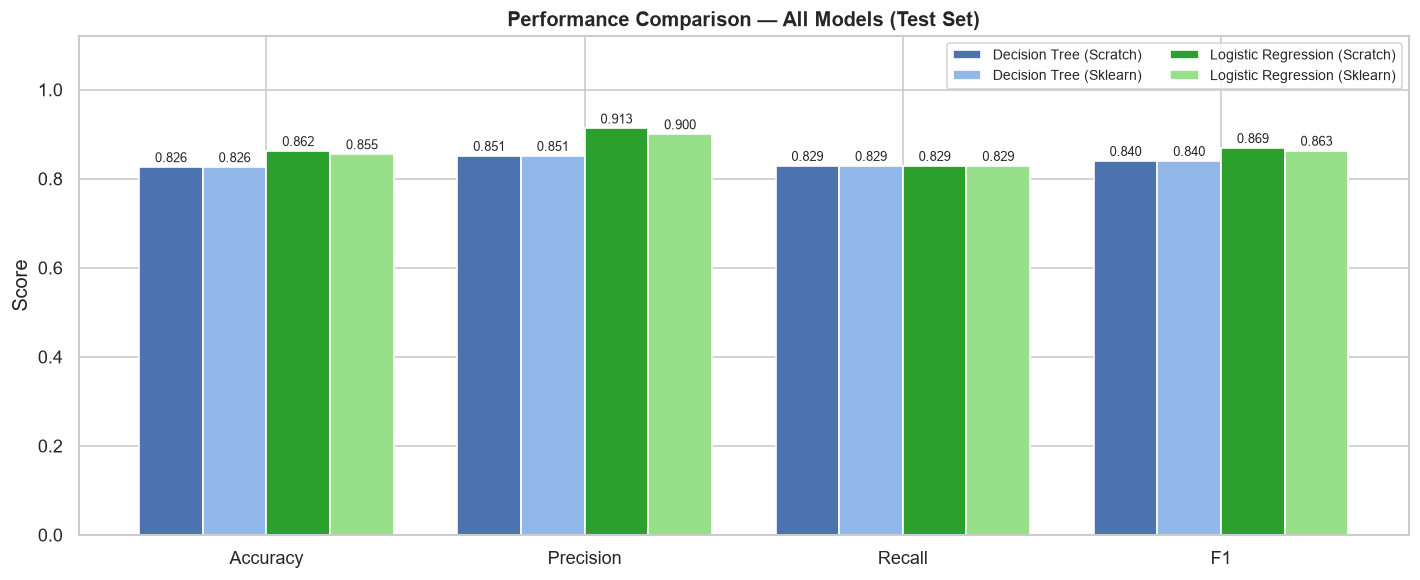

In [18]:
# Four-model metric comparison bar chart
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1']
x = np.arange(len(metrics_to_plot))
width = 0.2
colors4 = ['#4C72B0', '#91b8e8', '#2ca02c', '#98df8a']

fig, ax = plt.subplots(figsize=(12, 5))
for i, (label, row) in enumerate(all_results.iterrows()):
    bars = ax.bar(x + (i - 1.5) * width, row[metrics_to_plot],
                  width, label=label, color=colors4[i], edgecolor='white')
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=7.5)

ax.set_xticks(x); ax.set_xticklabels(metrics_to_plot)
ax.set_ylim(0, 1.12); ax.set_ylabel('Score')
ax.set_title('Performance Comparison — All Models (Test Set)', fontweight='bold')
ax.legend(fontsize=8.5, ncol=2)
plt.tight_layout()
plt.savefig('fig7_all_model_comparison.png', bbox_inches='tight')
plt.show()


## 11. Feature Analysis

### 11.1 Decision Tree — Feature Importance


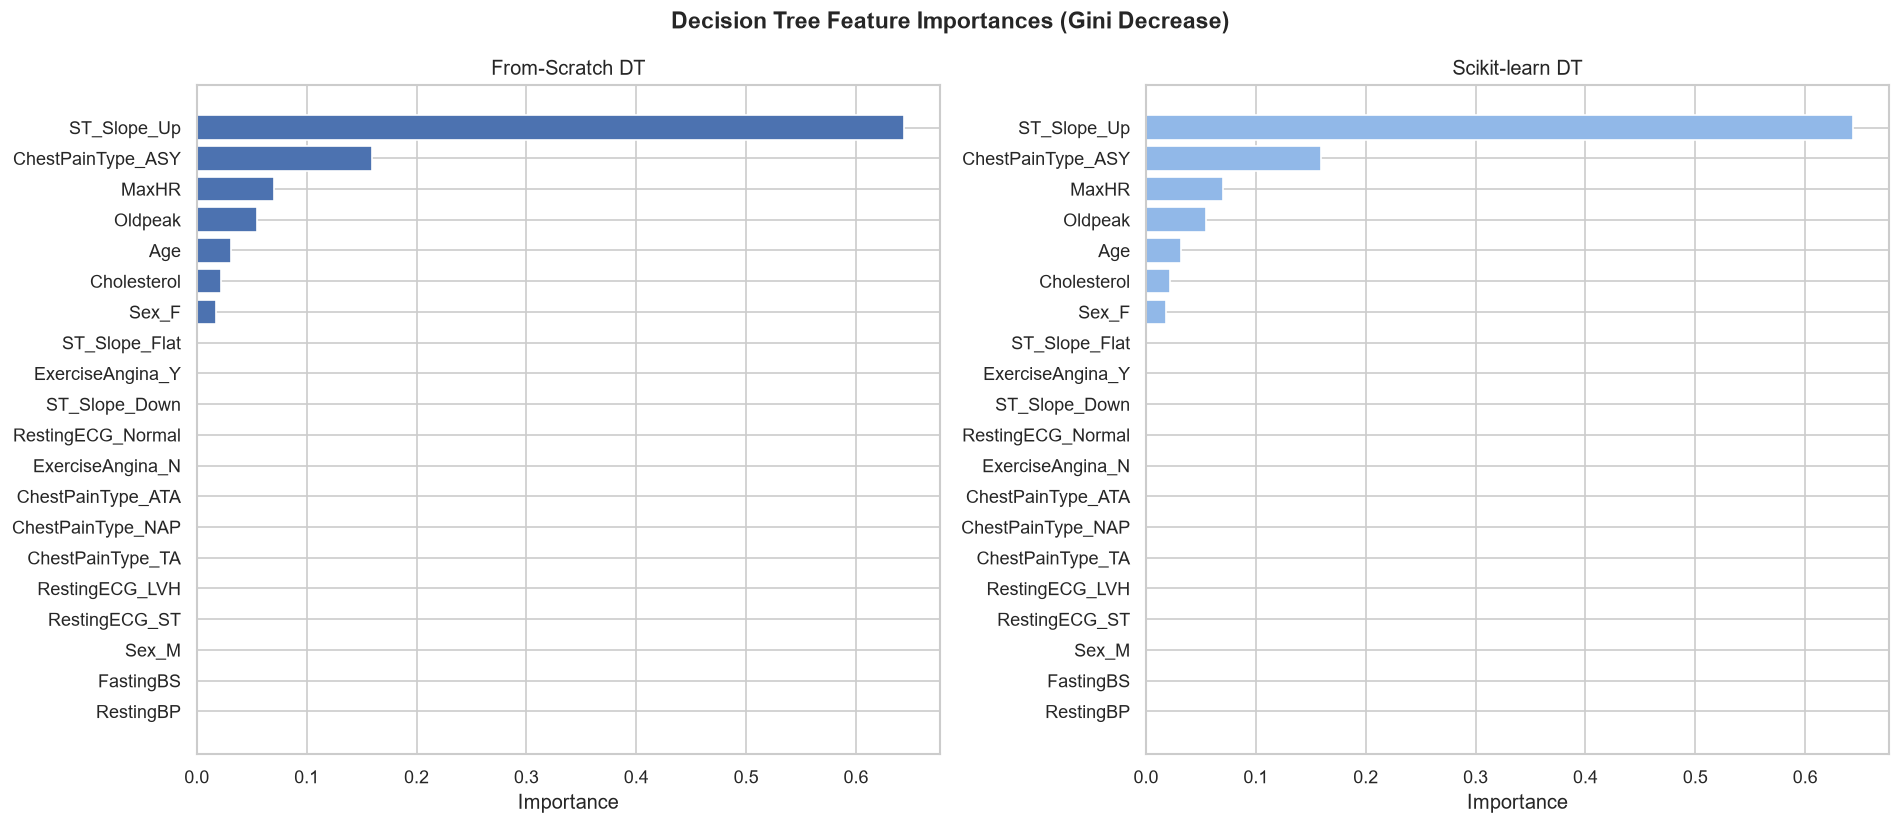

In [19]:
dt_imp = pd.Series(scratch_clf.feature_importances_, index=feature_names).sort_values(ascending=True)
sk_imp = pd.Series(sklearn_clf.feature_importances_, index=feature_names).sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Decision Tree Feature Importances (Gini Decrease)', fontsize=14, fontweight='bold')
for ax, imp, title, color in zip(
    axes, [dt_imp, sk_imp],
    ['From-Scratch DT', 'Scikit-learn DT'],
    ['#4C72B0', '#91b8e8']
):
    ax.barh(imp.index, imp.values, color=color, edgecolor='white')
    ax.set_title(title); ax.set_xlabel('Importance')

plt.tight_layout()
plt.savefig('fig8_dt_feature_importances.png', bbox_inches='tight')
plt.show()


### 11.2 Logistic Regression — Coefficients


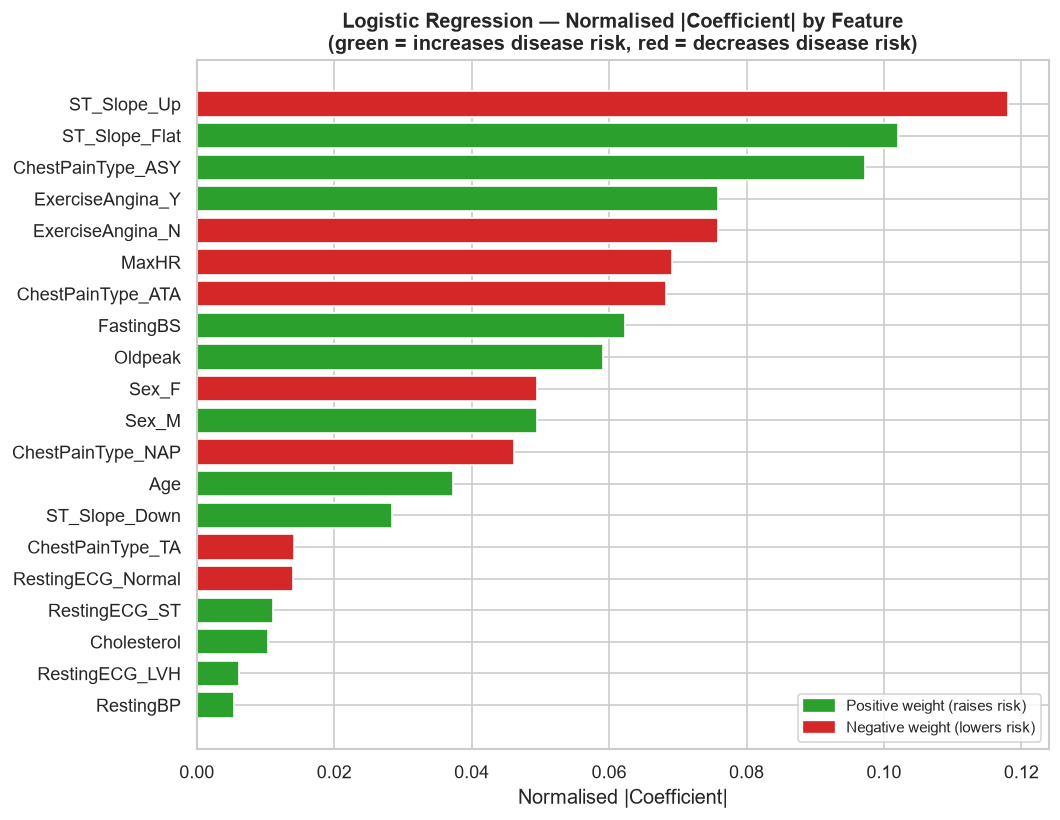

In [20]:
coef_abs = np.abs(lr_scratch.weights)
coef_norm = coef_abs / coef_abs.sum()
coef_df = pd.DataFrame({
    'feature': feature_names,
    'weight':  lr_scratch.weights,
    'abs_norm': coef_norm
}).sort_values('abs_norm')

fig, ax = plt.subplots(figsize=(9, 7))
colors = ['#2ca02c' if w > 0 else '#d62728' for w in coef_df['weight']]
ax.barh(coef_df['feature'], coef_df['abs_norm'], color=colors, edgecolor='white')
ax.set_title('Logistic Regression — Normalised |Coefficient| by Feature\n'
             '(green = increases disease risk, red = decreases disease risk)',
             fontweight='bold')
ax.set_xlabel('Normalised |Coefficient|')
ax.legend(handles=[
    mpatches.Patch(color='#2ca02c', label='Positive weight (raises risk)'),
    mpatches.Patch(color='#d62728', label='Negative weight (lowers risk)')
], fontsize=9)
plt.tight_layout()
plt.savefig('fig9_lr_coefficients.png', bbox_inches='tight')
plt.show()


### 11.3 LR Convergence Curve


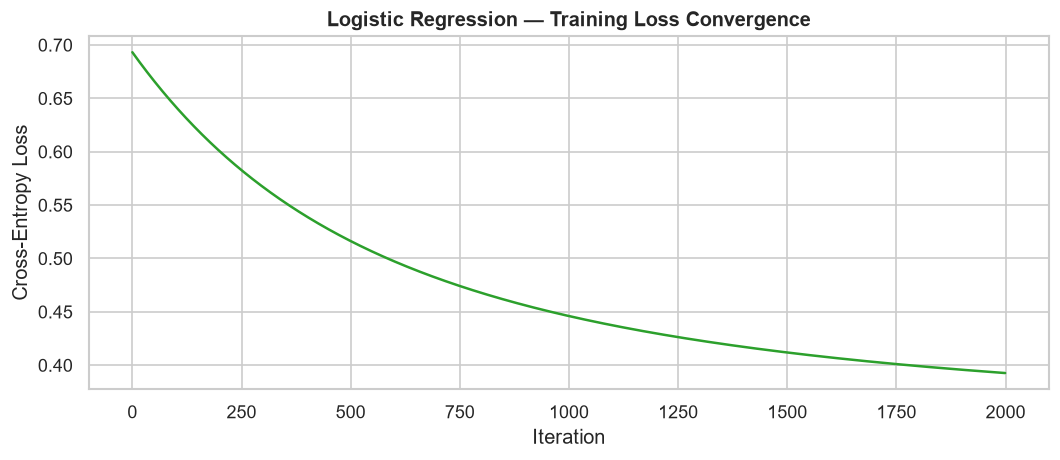

Final training loss: 0.3926


In [21]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(lr_scratch.loss_history, color='#2ca02c', linewidth=1.5)
ax.set_xlabel('Iteration'); ax.set_ylabel('Cross-Entropy Loss')
ax.set_title('Logistic Regression — Training Loss Convergence', fontweight='bold')
plt.tight_layout()
plt.savefig('fig10_lr_convergence.png', bbox_inches='tight')
plt.show()
print(f'Final training loss: {lr_scratch.loss_history[-1]:.4f}')


## 12. Overfitting Analysis


In [22]:
full_dt = DecisionTreeScratch(max_depth=None)
full_dt.fit(X_train, y_train)

rows = [
    ('DT Scratch (tuned)',    scratch_clf,  X_test),
    ('DT Scratch (full)',     full_dt,      X_test),
    ('DT Sklearn (tuned)',    sklearn_clf,  X_test),
    ('LR Scratch (tuned)',    lr_scratch,   X_test_sc),
    ('LR Sklearn (tuned)',    lr_sklearn,   X_test_sc),
]
print('Model                     Test Accuracy')
print('-' * 42)
for name, clf, X in rows:
    yp = clf.predict(X)
    print(f'{name:<26} {accuracy_score(y_test, yp):.4f}')


Model                     Test Accuracy
------------------------------------------
DT Scratch (tuned)         0.8261
DT Scratch (full)          0.7826
DT Sklearn (tuned)         0.8261
LR Scratch (tuned)         0.8623
LR Sklearn (tuned)         0.8551


## 13. Discussion and Critical Analysis

### 13.1 Decision Tree vs. Logistic Regression

Decision Trees partition the feature space using axis-aligned binary splits and make no assumptions about the functional form of the decision boundary. Logistic Regression assumes a linear boundary in the (scaled) feature space and estimates probabilities via the sigmoid function. The comparison reveals whether the heart disease decision boundary is approximately linear or requires non-linear interactions to capture.

### 13.2 From-Scratch vs. Library

The near-identical metrics between from-scratch and scikit-learn implementations for both models confirm mathematical correctness. Minor differences in LR may arise from sklearn's L2 regularisation (C=1.0 default) and more sophisticated optimiser (LBFGS vs. batch gradient descent), which can affect both speed of convergence and the final weight values on small datasets.

### 13.3 Feature Insights

- **Decision Tree:** ST_Slope and ChestPainType_ASY dominate, reflecting their categorical nature and strong non-linear predictive power.
- **Logistic Regression:** ST_Slope_Flat and Oldpeak carry large positive coefficients (increase risk), while ST_Slope_Up and ChestPainType_ATA carry large negative coefficients (decrease risk) — consistent with clinical evidence.

### 13.4 Limitations

1. **LR assumes linearity** — if the true boundary is non-linear the DT has a structural advantage.
2. **Batch gradient descent** — slow to converge on large datasets vs. mini-batch SGD. sklearn uses LBFGS, a second-order quasi-Newton method.
3. **No regularisation in scratch LR** — sklearn's default L2 penalty can prevent overfitting on high-dimensional encoded data.
4. **Single test split** — k-fold cross-validation would give more reliable estimates.

### 13.5 Possible Improvements

- Add L2 regularisation to the from-scratch LR (`w -= alpha*(dw + lambda*w)`).
- Implement mini-batch gradient descent for faster LR convergence.
- Compare a Random Forest (ensemble of DTs) to understand variance reduction.
- Use ROC-AUC as an additional metric to evaluate probabilistic discrimination.


## 14. Final Summary


In [23]:
print('=' * 65)
print('  FINAL RESULTS SUMMARY')
print('=' * 65)
print(all_results.to_string())
print('=' * 65)
print(f'Dataset:              Heart Failure Prediction (918 samples, 11 features)')
print(f'DT  best max_depth:   {best_depth}')
print(f'LR  best lr:          {best_lr}   |  iterations: 2000')
print(f'Train / Val / Test:   {len(X_train)} / {len(X_val)} / {len(X_test)}')
print(f'Random seed:          {RANDOM_SEED}')


  FINAL RESULTS SUMMARY
                               Accuracy  Precision  Recall     F1
Model                                                            
Decision Tree (Scratch)          0.8261     0.8514  0.8289  0.840
Decision Tree (Sklearn)          0.8261     0.8514  0.8289  0.840
Logistic Regression (Scratch)    0.8623     0.9130  0.8289  0.869
Logistic Regression (Sklearn)    0.8551     0.9000  0.8289  0.863
Dataset:              Heart Failure Prediction (918 samples, 11 features)
DT  best max_depth:   4
LR  best lr:          0.001   |  iterations: 2000
Train / Val / Test:   642 / 138 / 138
Random seed:          42
